In [2]:
import os

os.chdir(r'C:\Users\pm27995\Downloads')

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

file_name = "Grades_Summary.xlsx"

sheets = ["Spring2023", "Spring2024", "Spring2026"]

quizzes = [
    "Quiz1", "Quiz2", "Quiz3",
    "Quiz4", "Quiz5", "Quiz6"
]

assignments = [
    "Assignment1", "Assignment2", "Assignment3","Assignment4", "Assignment5", "Assignment6","Assignment7", "Assignment8", "Assignment9"
]

assessment_order = [
    "Assignment1",
    "Assignment2",
    "Quiz1",
    "Assignment3",
    "Assignment4",
    "Quiz2",
    "Midterm1",
    "Assignment5",
    "Assignment6",
    "Quiz4",
    "Assignment7",
    "Assignment8",
    "Quiz5",
    "Assignment9",
    "Quiz6",
    "Midterm2",
]

data = {}

for sheet in sheets:

    df = pd.read_excel(file_name, sheet_name=sheet)

    # Convert blanks to NaN
    df = df.replace(r"^\s*$", np.nan, regex=True)
    df = df.replace(0, np.nan)

    # Convert quizzes to percentage
    for quiz in quizzes:
        df[quiz] = pd.to_numeric(
            df[quiz], errors="coerce"
        ) / 20.0 * 100.0

    for assignment in assignments:
        df[assignment] = pd.to_numeric(
            df[assignment], errors="coerce"
        ) / 20.0 * 100.0

    # Convert midterms to percentage
    for midterm in ["Midterm1", "Midterm2"]:
        if midterm in df.columns:
            df[midterm] = pd.to_numeric(
                df[midterm], errors="coerce"
            ) / 50.0 * 100.0

    data[sheet] = df

# Fill missing values with NaN
for sheet in data:
    data[sheet] = data[sheet].replace(r"^\s*$", np.nan, regex=True)

# ============================================================
# Plot quiz PDFs
# ============================================================

colors = {
    "Spring2023": "tab:blue",
    "Spring2024": "tab:orange",
    "Spring2026": "tab:green"
}

data["Spring2023"]


,ID,Semester,Assignment1,Assignment2,Assignment3,Assignment4,Assignment5,Assignment6,Assignment7,Assignment8,...,Assignment10,Assignment10.1,Quiz1,Quiz2,Quiz3,Quiz4,Quiz5,Quiz6,Midterm1,Midterm2
0,1,Spring23,100.0,100.00,100.00,100.0,100.0,100.0,100.0,100.0,...,20.0,20.0,100.00,100.00,100.00,100.0,100.00,100.0,100.0,100.0
1,2,Spring23,104.5,100.00,100.00,90.0,90.0,100.0,100.0,100.0,...,20.0,18.0,93.75,92.50,110.00,NaN,98.75,100.0,102.0,100.0
2,3,Spring23,105.0,100.00,95.00,100.0,100.0,95.0,100.0,95.0,...,20.0,18.0,86.25,97.50,102.50,110.0,95.00,70.0,89.0,95.0
3,4,Spring23,105.0,100.00,100.00,90.0,100.0,100.0,100.0,100.0,...,17.0,NaN,100.00,95.00,110.00,NaN,97.50,87.5,104.0,100.0
4,5,Spring23,105.0,100.00,97.50,90.0,100.0,100.0,100.0,100.0,...,20.0,NaN,98.75,80.00,107.50,92.5,100.00,NaN,102.0,93.0
5,6,Spring23,104.0,95.00,97.50,82.0,70.0,NaN,70.0,NaN,...,16.0,20.0,77.50,81.25,92.50,50.0,78.75,42.5,84.0,81.0
6,7,Spring23,105.0,100.00,97.50,90.0,100.0,100.0,100.0,100.0,...,20.0,20.0,100.00,95.00,110.00,100.0,97.50,NaN,102.0,102.0
7,8,Spring23,105.0,100.00,100.00,95.0,100.0,100.0,95.0,100.0,...,20.0,20.0,95.00,87.50,110.00,67.5,NaN,67.5,94.0,93.0
8,9,Spring23,100.0,97.50,45.00,NaN,92.5,90.0,75.0,85.0,...,20.0,20.0,83.75,77.50,95.00,87.5,NaN,80.0,89.5,90.0
9,10,Spring23,105.0,95.00,100.00,100.0,90.0,90.0,100.0,100.0,...,20.0,20.0,70.00,100.00,90.00,77.5,90.00,70.0,89.0,96.0


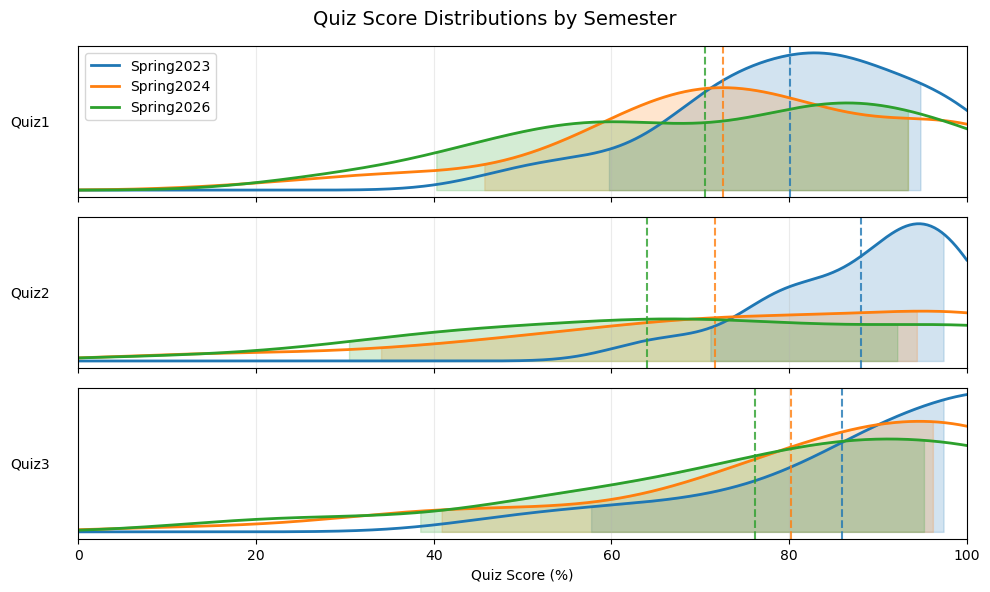

In [23]:
# ============================================================
# Plot quiz distributions: P10-P90 + P50
# ============================================================

colors = {
    "Spring2023": "tab:blue",
    "Spring2024": "tab:orange",
    "Spring2026": "tab:green"
}

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(10, 6),
    sharex=True
)

x = np.linspace(0, 100, 500)

for ax, quiz in zip(axes, quizzes[:3]):

    for semester in sheets:

        values = data[semester][quiz].dropna().values

        if len(values) < 2:
            continue

        kde = gaussian_kde(values)
        pdf = kde(x)

        # CDF of the KDE
        dx = x[1] - x[0]
        cdf = np.cumsum(pdf) * dx
        cdf /= cdf[-1]

        # Find P10, P50, P90 of the distribution
        p10 = np.interp(0.10, cdf, x)
        p50 = np.interp(0.50, cdf, x)
        p90 = np.interp(0.90, cdf, x)

        # PDF height at the percentile locations
        y10 = np.interp(p10, x, pdf)
        y50 = np.interp(p50, x, pdf)
        y90 = np.interp(p90, x, pdf)

        # Plot PDF
        ax.plot(
            x,
            pdf,
            color=colors[semester],
            linewidth=2,
            label=semester
        )

        # Shade the P10-P90 region of the PDF
        mask = (x >= p10) & (x <= p90)

        ax.fill_between(
            x[mask],
            pdf[mask],
            0,
            color=colors[semester],
            alpha=0.20
        )

        # Mark median
        ax.axvline(
            p50,
            color=colors[semester],
            linestyle="--",
            linewidth=1.5,
            alpha=0.8
        )

    ax.set_ylabel(
        quiz,
        rotation=0,
        labelpad=35,
        va="center"
    )

    ax.set_yticks([])
    ax.grid(True, axis="x", alpha=0.25)

axes[-1].set_xlabel("Quiz Score (%)")
axes[-1].set_xlim(0, 100)

axes[0].legend(loc="upper left")

fig.suptitle(
    "Quiz Score Distributions by Semester",
    fontsize=14
)

plt.tight_layout()
plt.show()

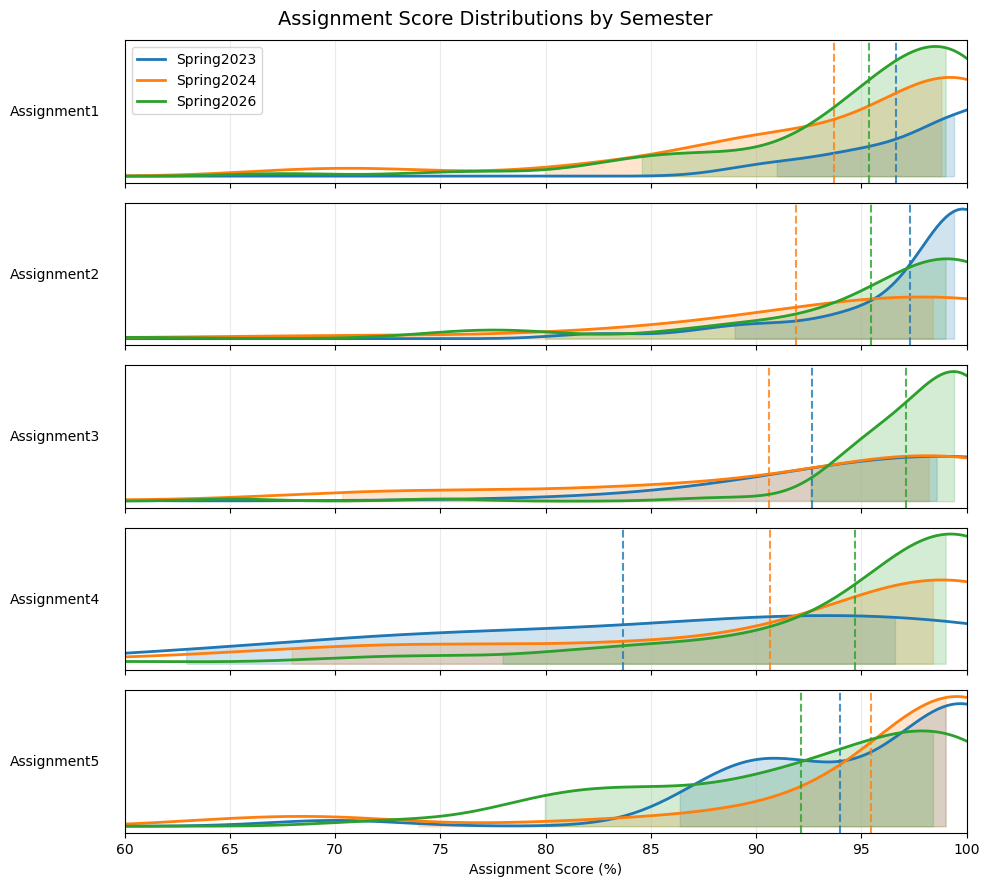

In [29]:
# ============================================================
# Plot Assignment PDFs: P10-P90 + P50
# ============================================================

assignments = [
    "Assignment1",
    "Assignment2",
    "Assignment3",
    "Assignment4",
    "Assignment5"
]

fig, axes = plt.subplots(
    nrows=5,
    ncols=1,
    figsize=(10, 9),
    sharex=True
)

x = np.linspace(0, 100, 500)

for ax, assignment in zip(axes, assignments):

    for semester in sheets:

        values = pd.to_numeric(
            data[semester][assignment],
            errors="coerce"
        ).dropna().values

        if len(values) < 2:
            continue

        # KDE
        kde = gaussian_kde(values)
        pdf = kde(x)

        # CDF of KDE
        dx = x[1] - x[0]
        cdf = np.cumsum(pdf) * dx
        cdf /= cdf[-1]

        # P10, P50, P90
        p10 = np.interp(0.10, cdf, x)
        p50 = np.interp(0.50, cdf, x)
        p90 = np.interp(0.90, cdf, x)

        # Plot PDF
        ax.plot(
            x,
            pdf,
            color=colors[semester],
            linewidth=2,
            label=semester
        )

        # Shade P10-P90
        mask = (x >= p10) & (x <= p90)

        ax.fill_between(
            x[mask],
            pdf[mask],
            0,
            color=colors[semester],
            alpha=0.20
        )

        # Median
        ax.axvline(
            p50,
            color=colors[semester],
            linestyle="--",
            linewidth=1.5,
            alpha=0.8
        )

    ax.set_ylabel(
        assignment,
        rotation=0,
        labelpad=50,
        va="center"
    )

    ax.set_yticks([])
    ax.grid(True, axis="x", alpha=0.25)

axes[-1].set_xlabel("Assignment Score (%)")
axes[-1].set_xlim(60, 100)

axes[0].legend(loc="upper left")

fig.suptitle(
    "Assignment Score Distributions by Semester",
    fontsize=14
)

plt.tight_layout()
plt.show()

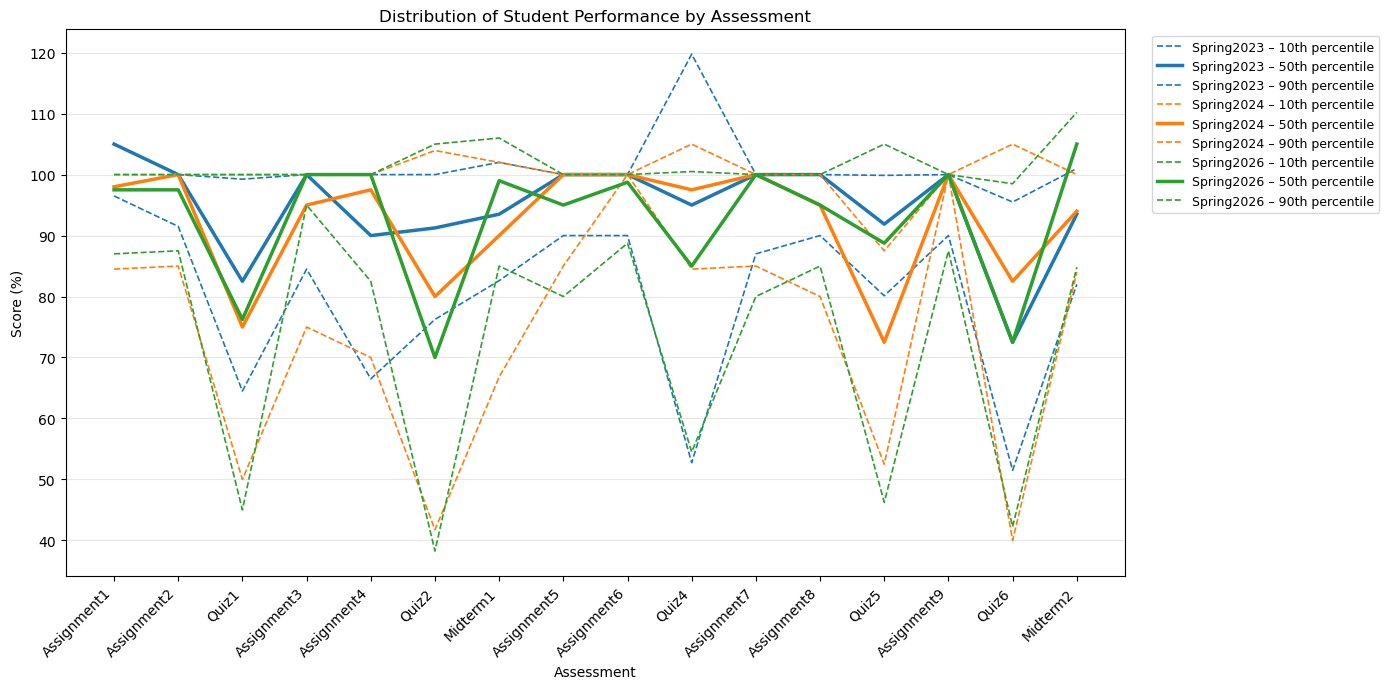

In [18]:

# ============================================================
# Calculate percentiles
# ============================================================

percentiles = [10, 50, 90]

results = {}

for semester, df in data.items():

    # Make sure assessment columns are numeric
    for col in assessment_order:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    # Calculate percentile across students
    results[semester] = pd.DataFrame(
        {
            col: np.nanpercentile(df[col].dropna(), percentiles)
            if df[col].notna().any()
            else [np.nan] * len(percentiles)
            for col in assessment_order
        },
        index=percentiles
    )

# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=(14, 7))

# One color per semester
colors = {
    "Spring2023": "tab:blue",
    "Spring2024": "tab:orange",
    "Spring2026": "tab:green"
}

# Different line styles for percentiles
linestyles = {
    10: "--",
    50: "-",
    90: "--"
}

# Slightly different transparency for the percentile lines
linewidths = {
    10: 1.2,
    50: 2.5,
    90: 1.2
}

x = np.arange(len(assessment_order))

for semester in sheets:

    result = results[semester]

    for percentile in percentiles:

        y = result.loc[percentile].values

        ax.plot(
            x,
            y,
            color=colors[semester],
            linestyle=linestyles[percentile],
            linewidth=linewidths[percentile],
            label=f"{semester} – {percentile}th percentile"
        )

# ============================================================
# Formatting
# ============================================================

ax.set_xticks(x)
ax.set_xticklabels(
    assessment_order,
    rotation=45,
    ha="right"
)

ax.set_ylabel("Score (%)")
ax.set_xlabel("Assessment")

ax.set_title(
    "Distribution of Student Performance by Assessment"
)

ax.grid(True, axis="y", alpha=0.3)

# Put legend outside plot
ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9
)

plt.tight_layout()
plt.show()

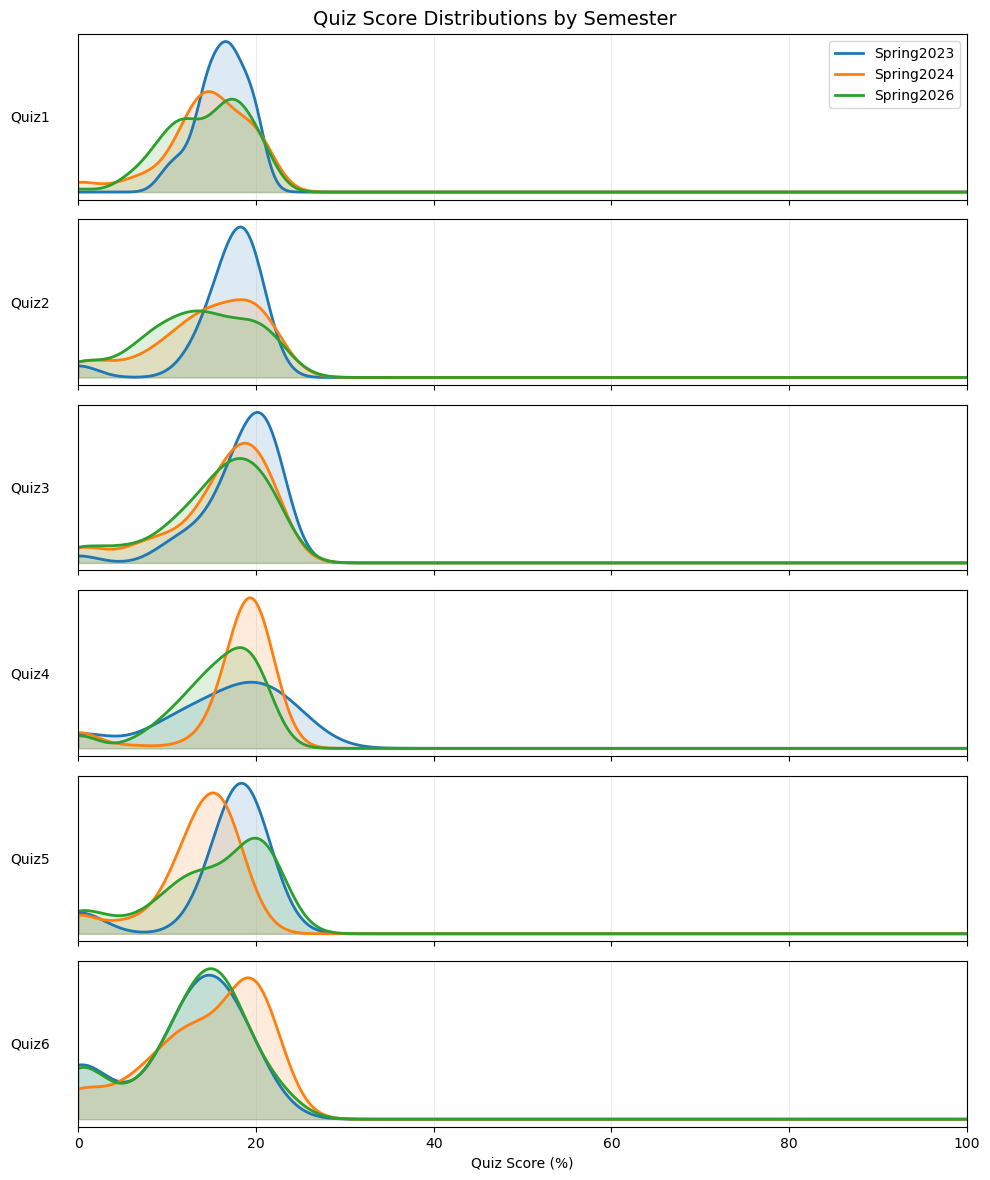

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import gaussian_kde

# ============================================================
# Plot quiz PDFs
# ============================================================

quizzes = [
    "Quiz1",
    "Quiz2",
    "Quiz3",
    "Quiz4",
    "Quiz5",
    "Quiz6"
]

colors = {
    "Spring2023": "tab:blue",
    "Spring2024": "tab:orange",
    "Spring2026": "tab:green"
}

fig, axes = plt.subplots(
    nrows=6,
    ncols=1,
    figsize=(10, 12),
    sharex=True
)

x = np.linspace(0, 100, 500)

for ax, quiz in zip(axes, quizzes):

    for semester in sheets:

        # Convert to numeric and remove missing values
        values = pd.to_numeric(
            data[semester][quiz],
            errors="coerce"
        ).dropna().values

        # Skip if insufficient data
        if len(values) < 2:
            continue

        # KDE
        kde = gaussian_kde(values)
        pdf = kde(x)

        # Plot sideways PDF
        ax.plot(
            x,
            pdf,
            color=colors[semester],
            linewidth=2,
            label=semester
        )

        # Fill underneath
        ax.fill_between(
            x,
            pdf,
            alpha=0.15,
            color=colors[semester]
        )

    ax.set_ylabel(quiz, rotation=0, labelpad=35, va="center")
    ax.set_yticks([])

    ax.grid(
        True,
        axis="x",
        alpha=0.25
    )

# Common x-axis
axes[-1].set_xlabel("Quiz Score (%)")
axes[-1].set_xlim(0, 100)

# One legend
axes[0].legend(
    loc="upper right"
)

fig.suptitle(
    "Quiz Score Distributions by Semester",
    fontsize=14
)

plt.tight_layout()
plt.show()